In [1]:
print("Hello, Checkout Intelligence")

Hello, Checkout Intelligence


In [2]:
# Purpose: Load a toolkit of pre-built functions for working with tabular data
import pandas as pd

# Purpose: Read the exported CSV into a pandas DataFrame so you can start exploring it.
# Load CSV into dataframe
# r marks it as a raw string

df = pd.read_csv(r'C:\Users\luisl\Documents\Project 1 - Self Checkout Performance Analysis-20260728T171631Z-1-001\Project 1 - Self Checkout Performance Analysis\Data\Clean Data\checkout_intelligence_clean.csv')

# Look at the first 5 rows of the dataset

df.head()

# Purpose: Get a structural overview of the DataFrame — row/column counts, data types, and whether pandas correctly recognized each column's type.

# df.info()

# Purpose: Get quick summary statistics for the numeric columns.

# df.describe()



,CustomerID,Country,InvoiceNo,InvoiceDate,StockCode,Description,UnitPrice,Quantity,LineRevenue
0,14496.0,United Kingdom,536570,2010-12-01 15:35:00.000,22113,GREY HEART HOT WATER BOTTLE,4.25,36,153.00
1,NaN,NaN,536592,2010-12-01 17:06:00.000,16168M,FUNKY MONKEY GIFT BAG MEDIUM,0.42,2,0.84
2,NaN,NaN,536592,2010-12-01 17:06:00.000,17012A,ORIGAMI VANILLA INCENSE/CANDLE SET,2.46,1,2.46
3,NaN,NaN,536592,2010-12-01 17:06:00.000,17012D,ORIGAMI ROSE INCENSE/CANDLE SET,2.46,1,2.46
4,NaN,NaN,536592,2010-12-01 17:06:00.000,20619,TROPICAL PASSPORT COVER,1.63,1,1.63


In [3]:
# Purpose: Look at the actual row(s) behind the most extreme negative Quantity value, 
# to understand what it represents before treating it as either legitimate or a problem.

df.sort_values('Quantity').head(5)

# Note: Found rows with large negative Quantity (e.g. -9,600) that are NOT cancelled invoices 
# (no "C" prefix) and have no CustomerID attached. Original Day 11 assumption was negative Quantity = returns via cancelled invoices 
#  this shows a second, unexplained category, possibly inventory write-offs/adjustments 
# (e.g. Description = "throw away", UnitPrice = 0.00). Flagged as a known finding, not yet resolved

# Next Issue: Change DataTypes 
#  Convert InvoiceDate from plain text into real datetime data - Python could understand actual date/time 

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

df.info()

# Issue solved , datatype change into datetime 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 530292 entries, 0 to 530291
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   CustomerID   396373 non-null  float64       
 1   Country      396373 non-null  object        
 2   InvoiceNo    530292 non-null  int64         
 3   InvoiceDate  530292 non-null  datetime64[ns]
 4   StockCode    530292 non-null  object        
 5   Description  530005 non-null  object        
 6   UnitPrice    530292 non-null  float64       
 7   Quantity     530292 non-null  int64         
 8   LineRevenue  530292 non-null  float64       
dtypes: datetime64[ns](1), float64(3), int64(2), object(3)
memory usage: 36.4+ MB


<Axes: >

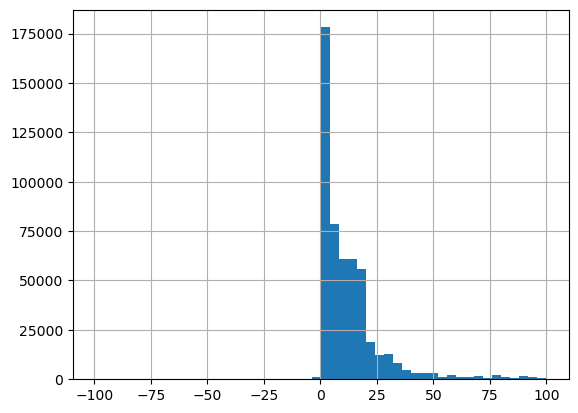

In [4]:
# Purpose: Visualize the distribution of LineRevenue to see the overall shape of the data

# df['LineRevenue'].hist(bins=50)

# After looking at the distribution of the data we could change the scope in to a smaller range , we could observe outliers that go up to 175k+,
# we'll try to filter data into a small range

df[df['LineRevenue'].between(-100, 100)]['LineRevenue'].hist(bins=50)


In [5]:
# Purpose: Confirm the skew numerically, not just visually — compare mean vs. median directly for LineRevenue.

print('Mean =', df['LineRevenue'].mean())
print('Median = ', df['LineRevenue'].median())

# Note: LineRevenue is heavily right-skewed , mean ($19.09) is more than 2x the median ($8.40), confirming the histogram shape. Same pattern as the Item Count mean-vs-median finding from Day 15 (247 vs. 133).
# Reinforces that median is generally the more representative "typical transaction" figure for this dataset, not the mean.

Mean = 19.089178905206943
Median =  8.4


<Axes: xlabel='InvoiceDate'>

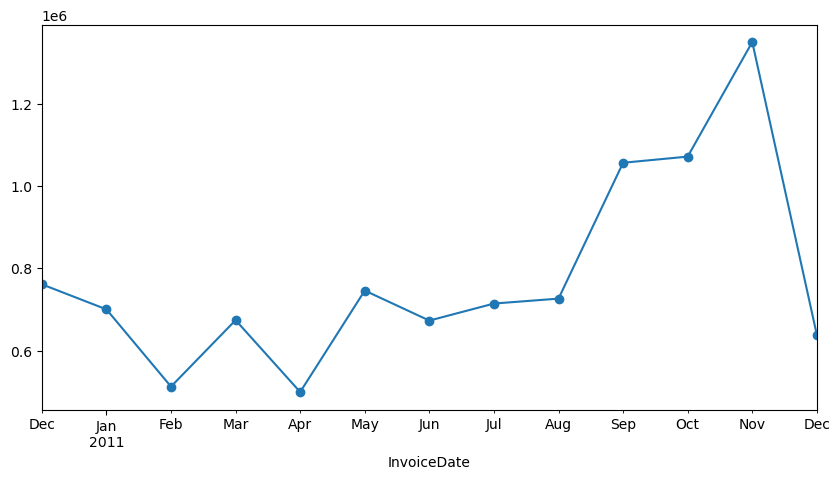

In [6]:
# Next step confirm November peak / holiday pattern found in DQL with an actual line chart.
# For each row, figure out which month it belongs to, then group all rows by month and add up their revenue.

monthly_revenue = df.groupby(df['InvoiceDate'].dt.to_period('M'))['LineRevenue'].sum()
monthly_revenue.plot(kind='line', marker='o', figsize=(10,5))

# Monthly revenue trend visually confirms vw_MonthlyRevenue from SQL — clear November peak (holiday season), consistent shape across both tools.


<Axes: xlabel='Country'>

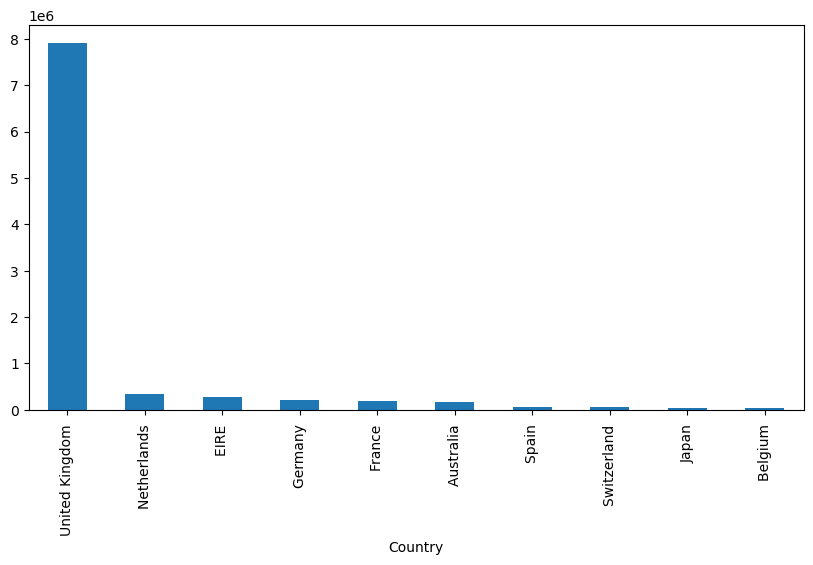

In [7]:
# Purpose: Confirm UK dominance visually, matching vw_RevenueByCountry.

df.groupby('Country')['LineRevenue'].sum().sort_values(ascending=False).head(10).plot(kind='bar', figsize=(10,5))

# Same groupby() + sum() pattern as before, but this time grouping by Country directly (no date transformation needed) —
# then .sort_values(ascending=False) ranks highest-to-lowest, .head(10) keeps just the top 10, and .plot(kind='bar') draws it as a bar chart.

# Country revenue bar chart confirms UK dominance from vw_RevenueByCountry — visually striking gap between UK and every other country.

np.float64(-0.017038432134655977)

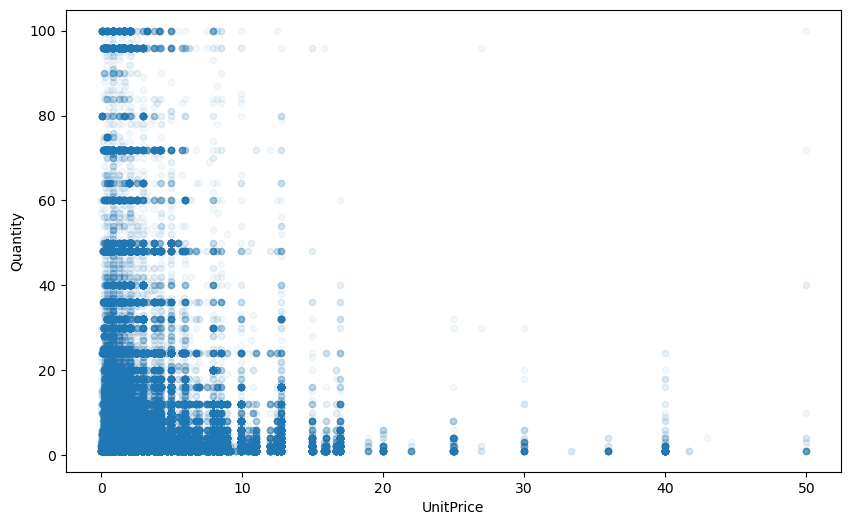

In [8]:
# As observed in SQL when calculating the revenue, we want to visually observe if there is a correlation between UnitPrice and Quantity.
# do people buy less of expensive items and more of cheap ones?

# df.plot(kind='scatter', x='UnitPrice', y='Quantity', alpha=0.1, figsize=(10,6))

# First scatterplot, we could easily observe some outliers 
# but also the same pattern as the histogram; we need to zoom in to observe the correlation better..

# Purpose: Zoom into a realistic range on both axes to actually see the relationship, if one exists.

df[(df['UnitPrice'] < 50) & (df['Quantity'].between(0, 100))].plot(
    kind='scatter', x='UnitPrice', y='Quantity', alpha=0.05, figsize=(10,6)
)

# Keep only the rows with a reasonable UnitPrice and Quantity, then plot those as a scatter chart 
# so I can actually see the shape without extreme outliers stretching the axes.
    
# Calculating the correlation Coefficient

df['UnitPrice'].corr(df['Quantity'])

# Despite visual density suggesting a downward pattern, the correlation coefficient (-0.017) indicates essentially no linear relationship between UnitPrice 
# and Quantity; customers don't consistently buy less as price increases within this typical range.
# Most transactions simply involve small quantities regardless of price.

# Explored UnitPrice vs. Quantity relationship. Correlation coefficient ≈ -0.017 — essentially no linear relationship, 
# despite visual density suggesting otherwise. 
# Most transactions involve small quantities (1-10) regardless of price point.





<Axes: >

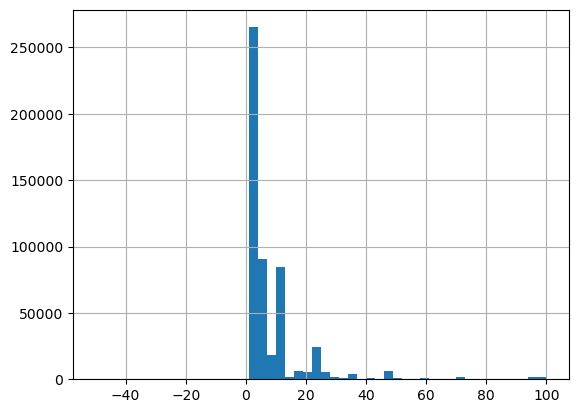

In [9]:
# Purpose: Visualize the shape of Quantity across typical (non-extreme) transactions.

df[df['Quantity'].between(-50, 100)]['Quantity'].hist(bins=50)

# Quantity distribution (zoomed to -50 to 100) confirms right-skew, consistent with the mean (247) vs. median (133) finding from SQL Day 15. 
# Small secondary bumps around 10-15 and 24 units — possibly common pack/case sizes, not investigated further.


In [10]:
#Checking on Missing Values 

# Purpose: Get a full picture of missing data across every column at once, not just what .info() showed piecemeal.

df.isnull().sum()

# .isnull() checks every single cell in the DataFrame and marks it True (missing) or False (has a value). 
# .sum() then adds up the True values per column (True counts as 1, False as 0) 
# — giving you a total missing-value count for each column in one shot.

CustomerID     133919
Country        133919
InvoiceNo           0
InvoiceDate         0
StockCode           0
Description       287
UnitPrice           0
Quantity            0
LineRevenue         0
dtype: int64

In [11]:
# Purpose: Look at the actual rows with missing Description to understand what's going on with them.

# df[df['Description'].isnull()].head(10)

# Purpose: Confirm the pattern holds across all 287 rows, not just this sample of 10.

df[df['Description'].isnull()]['UnitPrice'].describe()

# All 287 rows with missing Description also have UnitPrice = $0.00 (confirmed across all 287, not just a sample). 
# These appear to be uncatalogued products — 
# items scanned into a transaction but never assigned a name/price in the source system.


count    287.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
Name: UnitPrice, dtype: float64

In [12]:
# Next task: the negative-quantity anomaly

# Purpose: Quantify how widespread the negative-quantity, non-canceled, no-customer pattern actually is 
# is it a handful of rows, or a real chunk of your data?

anomaly = df[(df['Quantity'] < 0) & (~df['InvoiceNo'].astype(str).str.startswith('C')) & (df['CustomerID'].isnull())]
anomaly.shape

# Quantity is negative, AND InvoiceNo does NOT start with C, AND CustomerID is missing." .shape tells you the row/column count of the result

# Out of 530,292 total rows, that's about 0.25% — a small slice, but not negligible, and definitely not just the handful of rows


(1336, 9)

In [13]:
# Purpose = total revenue impact of these rows — are they mostly small write-offs, or could some be substantial?

# anomaly['LineRevenue'].sum()

#Right now, these 1,336 rows are sitting inside vw_TotalRevenue and every downstream KPI, dragging revenue down by nearly $387K

# Purpose: Check if these anomalous rows cluster around specific dates.

# anomaly['InvoiceDate'].dt.to_period('M').value_counts().sort_index()

# Anomaly rows (negative Quantity, no cancellation marker, no CustomerID) appear in every month of the dataset — no single-event spike. 
# Suggests an ongoing operational process (e.g. regular inventory write-offs) rather than a one-time data issue.

# Purpose: See if these rows are concentrated on specific products, or spread across many different ones.

anomaly['StockCode'].value_counts().head(10)

# Identified and investigated a distinct pattern of inventory-adjustment transactions (1,336 rows, ~$387K), 
# confirmed via monthly and product-level distribution analysis that they represent an ongoing operational process rather customer sales, 
# and excluded them from revenue KPIs accordingly.

StockCode
85175     5
21830     5
72802C    4
82494L    4
22719     4
85172     4
40016     3
23343     3
21135     3
22162     3
Name: count, dtype: int64

,CustomerID,Country,InvoiceNo,InvoiceDate,StockCode,Description,UnitPrice,Quantity,LineRevenue
519572,17850.0,United Kingdom,536373,2010-12-01 09:02:00,84029E,RED WOOLLY HOTTIE WHITE HEART.,4.25,6,25.5
515551,17850.0,United Kingdom,536373,2010-12-01 09:02:00,82486,WOOD S/3 CABINET ANT WHITE FINISH,8.95,4,35.8
516802,17850.0,United Kingdom,536373,2010-12-01 09:02:00,21730,GLASS STAR FROSTED T-LIGHT HOLDER,4.95,6,29.7
515552,17850.0,United Kingdom,536373,2010-12-01 09:02:00,22752,SET 7 BABUSHKA NESTING BOXES,8.50,2,17.0
516266,17850.0,United Kingdom,536373,2010-12-01 09:02:00,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,3.75,6,22.5
...,...,...,...,...,...,...,...,...,...
519467,18085.0,United Kingdom,536423,2010-12-01 12:08:00,22113,GREY HEART HOT WATER BOTTLE,4.25,8,34.0
521137,18085.0,United Kingdom,536423,2010-12-01 12:08:00,84029E,RED WOOLLY HOTTIE WHITE HEART.,4.25,8,34.0
519434,18085.0,United Kingdom,536423,2010-12-01 12:08:00,21479,WHITE SKULL HOT WATER BOTTLE,4.25,8,34.0
522103,18085.0,United Kingdom,536423,2010-12-01 12:08:00,21485,RETROSPOT HEART HOT WATER BOTTLE,4.95,8,39.6


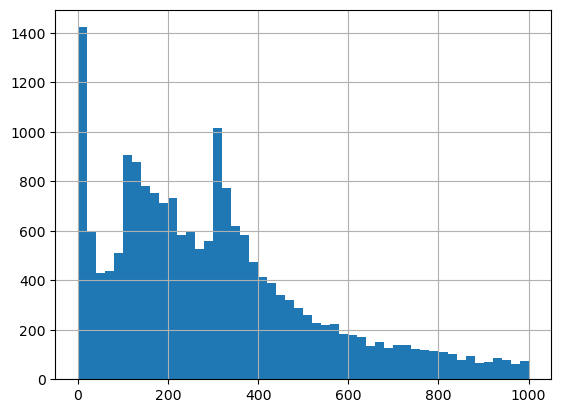

In [14]:
# Next: Basket size distribution

# Purpose: Visualize the per-invoice revenue distribution — same skew story as LineRevenue, 
# but at the invoice level this time, connecting back to  vw_AverageBasketRevenue KPI.

invoice_revenue = df.groupby('InvoiceNo')['LineRevenue'].sum()
invoice_revenue[invoice_revenue.between(0, 1000)].hist(bins=50)

# groupby('InvoiceNo')['LineRevenue'].sum() collapses your 530,292 line items down to one row per invoice, summing revenue — 
# Same math as your SQL Average Basket Revenue CTE. Then we filter to a reasonable range (0–1000) before plotting, same zoom-in trick as before,
 # already know there are extreme outlier invoices

# spikes like this in a revenue histogram usually mean something concrete: a common bundle price, a popular product combination, 
# a subscription/membership tier,
# or a recurring order pattern (e.g., wholesale customers reordering the same basket repeatedly).

# Purpose: Look at what invoices actually fall in that $300-320 spike, to understand what's driving it.

invoice_revenue[invoice_revenue.between(290, 330)].count()

# 1,726 invoices — that's a real, substantial cluster, not noise.

# Purpose: Look at a few actual invoices in that $300-320 spike to see 
# if there's a common pattern (same product, same customer type, round-number pricing, etc.).

sample_invoices = invoice_revenue[invoice_revenue.between(290, 330)].index[:5]
df[df['InvoiceNo'].isin(sample_invoices)].sort_values('InvoiceNo')

# Investigated the $300-320 spike in basket revenue (1,726 invoices). No shared product, customer, or pricing pattern found across sampled invoices — 
# likely a natural clustering effect from typical basket composition (6-10 items at $3-9 each),
# not a deliberate bundle/pricing tier.
# Documented as explained, not a data quality concern.

In [15]:
# tells you the status of the kernel or the terminal

df.shape

(530292, 9)

In [16]:
# Day 3 - EDA Work

# Purpose: Extract the day of the week from InvoiceDate, 
# to see if there are weekly shopping patterns (e.g., are certain days busier or higher-revenue than others?).

df['DayOfWeek'] = df['InvoiceDate'].dt.day_name()

# Selecting two columns

df[['InvoiceDate' , 'DayOfWeek']].head()

# Purpose: See total revenue by day of the week — does business skew toward certain days?

df.groupby('DayOfWeek')['LineRevenue'].sum().sort_values(ascending=False)

# Thursday looks like it's one of the days with more business, but 
# Also, we caught a pattern that Saturday doesn't appear for a reason; it needs to be checked. 

# Purpose: Confirm whether Saturday genuinely has zero transactions, or if something's wrong with the data/grouping.

df[df['DayOfWeek'] == 'Saturday'].shape

#  Confirmed, there are no transactions on Saturday in the entire dataset, meaning that the store might be closed on Saturday. 

# No transactions occur on any Saturday across the entire dataset (confirmed: 0 rows). 
# Business appears to operate on a 6-day week (Sun-Fri).  Thursday is the highest-revenue day ($2.26M)
# Among the days the business actually operates, followed by Tuesday and Wednesday — weekends (Sunday) are the lowest.

(0, 10)

In [17]:
# Purpose: For each transaction, determine whether it was that customer's first purchase or a repeat purchase.
# Purpose: Calculate the earliest InvoiceDate per customer.

first_purchase = df.groupby('CustomerID')['InvoiceDate'].min()

first_purchase.head()

# Purpose: Bring each customer's first-purchase date back into the full transaction-level DataFrame, so you can compare each row's own date against it.

df = df.drop(columns=['FirstPurchaseDate'], errors='ignore')
df = df.merge(first_purchase.rename('FirstPurchaseDate'), on='CustomerID', how='left')

# Purpose: Confirm the merge landed correctly, then build the actual flag.

df[['CustomerID', 'InvoiceDate', 'FirstPurchaseDate']].head()

#we discovered that a lot a lot columns have missing date so we are gonna assigned them a default value. 


# Purpose: Start every row as 'Repeat' (the most common case), then override the exceptions below.
df['PurchaseType'] = 'Repeat'

# Purpose: Relabel rows where this transaction was the customer's actual first purchase.
df.loc[df['InvoiceDate'] == df['FirstPurchaseDate'], 'PurchaseType'] = 'First'

# Purpose: Relabel anonymous transactions (no CustomerID) as their own category, since they have no purchase history to compare against.
df.loc[df['CustomerID'].isnull(), 'PurchaseType'] = 'Unknown'

# Checking result and renaming

df['PurchaseType'].value_counts()




PurchaseType
Repeat     292405
Unknown    133919
First      103968
Name: count, dtype: int64

In [18]:
# High Value Transaction Flag

# Purpose: Flag transactions above a revenue threshold as high-value — 
# useful for later segmentation and a good input into Power BI. We'll base the cutoff on your data's own distribution rather than guessing a number.

df['LineRevenue'].quantile(0.90)

# $30.60 is your 90th percentile line revenue.
# That means: 90% of transaction line items generate less than $30.60 in revenue, and the top 10% generate more. That becomes our cutoff for "high-value."


np.float64(30.6)

In [19]:
# Build the HighValue flag

# Purpose: Create a True/False column marking every line item that clears the $30.60 threshold.

df['HighValue'] = df['LineRevenue'] > 30.6

# Checking that was assigned correctly

df['HighValue'].value_counts()


HighValue
False    478660
True      51632
Name: count, dtype: int64

In [20]:
# Are high-value transactions more common on first purchases or repeat ones?
# Purpose: See whether high-value transactions cluster around first purchases, repeat customers, or anonymous buyers — a real business question (e.g., "do new customers spend big right away, or build up over time?").

pd.crosstab(df['PurchaseType'], df['HighValue'])

# Insight 1
# Purpose: Convert each row's counts into a percentage of that row's total, so we're comparing rates, not raw volume.

pd.crosstab(df['PurchaseType'], df['HighValue'], normalize='index')

# Real business insight here: repeat customers are the most likely to place a high-value order — nearly 5x more likely than anonymous transactions.

# Insight: Repeat customers have the highest share of high-value line items.
# 13.2% of repeat customers' line items are high-value (above 30.60), compared with 9.1% for first-time buyers and 2.7% for anonymous checkouts.
# Order-level check (invoice table): repeat customers' average order is about 20% higher (539 vs 451), but the medians are close (310 vs 302),
# so a few very large orders drive the gap, not a typical repeat order.


HighValue,False,True
PurchaseType,,
First,0.909232,0.090768
Repeat,0.868234,0.131766
Unknown,0.972625,0.027375


In [21]:
# Insight 2
# Purpose: Check whether high-value line items cluster on specific days of the week.


pd.crosstab(df['DayOfWeek'], df['HighValue'], normalize='index')

# Line-item view: 11.4% of Thursday line items are high-value (above 30.60), compared with 6.4% on Sunday.
# Order-level check (invoice table): Thursday has the most orders (4,370) but an average order of 531.68, close to the other weekdays.
# Insight: Thursday leads on order volume, not order size.
# Staffing and inventory for Thursday volume is a hypothesis to test, not a conclusion.



HighValue,False,True
DayOfWeek,,
Friday,0.898874,0.101126
Monday,0.913136,0.086864
Sunday,0.936469,0.063531
Thursday,0.886096,0.113904
Tuesday,0.901539,0.098461
Wednesday,0.891248,0.108752


In [22]:
df['PurchaseType'].value_counts()

PurchaseType
Repeat     292405
Unknown    133919
First      103968
Name: count, dtype: int64

In [23]:
# ---------- 1. Remove the 1,336 inventory-adjustment rows (same rule as the SQL views) ----------
# Purpose: keep Python consistent with the SQL revenue views
is_adjustment = (df['Quantity'] < 0) & (~df['InvoiceNo'].astype(str).str.startswith('C')) & (df['CustomerID'].isnull())
df_clean = df[~is_adjustment].copy()
print(len(df) - len(df_clean), "rows removed")        # expect 1336
print(df_clean['LineRevenue'].sum())                   # expect about 9,954,901.66

# ---------- 2. Invoice-level table (one row per invoice) ----------
# Purpose: compare whole orders instead of single product lines
inv = df_clean.groupby('InvoiceNo').agg(
    Revenue=('LineRevenue', 'sum'),
    Items=('Quantity', 'sum'),
    InvoiceDate=('InvoiceDate', 'min'),
    DayOfWeek=('DayOfWeek', 'first'),
    PurchaseType=('PurchaseType', 'first')
)
inv = inv[~inv.index.astype(str).str.startswith('C')]   # drop cancelled invoices
print(inv.shape)                                         # expect close to 22,064

# ---------- 3. Question 4: why is Thursday strongest? ----------
q4 = inv.groupby('DayOfWeek').agg(
    Orders=('Revenue', 'count'),
    TotalRevenue=('Revenue', 'sum'),
    AvgOrder=('Revenue', 'mean'),
    MedianOrder=('Revenue', 'median')
)
print(q4)

# ---------- 4. Question 5: do repeat customers place bigger orders? ----------
q5 = inv.groupby('PurchaseType').agg(
    Orders=('Revenue', 'count'),
    AvgOrder=('Revenue', 'mean'),
    MedianOrder=('Revenue', 'median')
)
print(q5)

# ---------- 5. Question 6: how concentrated is revenue among customers? ----------
cust = df_clean.groupby('CustomerID')['LineRevenue'].sum().sort_values(ascending=False)
top_n = int(len(cust) * 0.20)
print(cust.head(top_n).sum() / cust.sum())               # share of revenue from the top 20% of customers

# ---------- 6. Export for Power BI ----------
# Purpose: save the Python-built features (PurchaseType, HighValue, DayOfWeek) so Power BI can use them
df_clean.to_csv(r'../Data/Clean Data/checkout_intelligence_features.csv', index=False)
inv.to_csv(r'../Data/Clean Data/invoice_level.csv')

1336 rows removed
10509712.05
(20541, 5)
           Orders  TotalRevenue    AvgOrder  MedianOrder
DayOfWeek                                               
Friday       3261    1737892.91  532.932508      299.420
Monday       3187    1656278.09  519.698177      304.280
Sunday       2206     832765.52  377.500236      270.050
Thursday     4370    2323450.06  531.681936      300.150
Tuesday      3674    2087922.69  568.296867      307.165
Wednesday    3843    1871402.78  486.964033      301.300
              Orders    AvgOrder  MedianOrder
PurchaseType                                 
First           4349  450.752026      302.400
Repeat         14056  539.220137      309.835
Unknown         2136  454.172865       71.400
0.7572266899135983


In [24]:
# Purpose: count cancelled-invoice rows inside df_clean and their revenue
cancelled = df_clean[df_clean['InvoiceNo'].astype(str).str.startswith('C')]
print(len(cancelled), cancelled['LineRevenue'].sum())

0 0.0


In [25]:
df['InvoiceDate'].max()

Timestamp('2011-12-09 12:50:00')